# 16장. 최종 프로젝트: 제조 AI 품질관리 시스템

「AI로 만드는 제조공정 품질관리 따라하기」 16장 실습 Notebook입니다. CPU 런타임으로 충분합니다.
새로 학습하지 않고, 앞 장들이 저장한 결과를 모읍니다. **5·6장, 9장, 13·14장, 15장 Notebook을 먼저 실행해야 합니다.**

세 데이터셋(SECOM, PHM 2016 CMP, MVTec AD)은 서로 다른 출처이며 같은 제조라인의 데이터가 아닙니다.
이 Notebook은 세 결과를 연결하지 않고, 같은 의사결정 틀(재검사 알람 / 추가 계측 / 엔지니어 재검토)로 나란히 정리합니다.

비용 시뮬레이션(결과를 보기 전에 정함): 모든 비용은 가정값입니다.
- 불량 위험(SECOM): 놓친 불량 10, 헛알람(재검사) 1 — 6장과 같은 가정
- 가상계측(CMP): 실측 1회 1, 실측하지 않은 웨이퍼가 허용오차(±5)를 넘으면 5 — 비율 2~20으로 바꿔 민감도 확인
- 이미지 판독(MVTec AD): 놓친 불량 10, 정상을 불량 처리 1, 재검토 1장 0.2 — 재검토 비용 0.05~1로 바꿔 민감도 확인

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    %cd /content/manufacturing-ai-tutorial/04-dashboard

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
TUT = ROOT.parent

In [2]:
import importlib.util
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec); sys.modules[name] = mod; spec.loader.exec_module(mod)
    return mod

## 16-1. 세 PoC의 결과 모으기

In [3]:
# (1) 불량 위험 예측: 5장 LR+KBest의 평가 데이터 확률, 6장의 임계값(OOF F1 최대)
su = load_module("secom_utils", TUT / "01-yield-risk/src/secom_utils.py")
X, y, ts = su.load_secom(TUT / "01-yield-risk/data/secom")
_, (_, y_test, ts_test) = su.dev_test_split(X, y, ts, test_size=0.2)
proba = np.load(TUT / "01-yield-risk/results/05_test_proba.npy", allow_pickle=True).item()["LR + SelectKBest(k=80, C=0.1)"]
th6 = json.loads((TUT / "01-yield-risk/results/06_threshold_shap.json").read_text(encoding="utf-8"))
row6 = next(r for r in th6["threshold_table"] if r["model"] == "LR+KBest" and r["rule"].startswith("max F1"))
alarm = proba >= row6["threshold"]
secom = pd.DataFrame({"ts": ts_test, "fail": y_test, "risk": proba.round(4), "alarm": alarm})
secom.to_csv("results/16_secom_scores.csv", index=False)
tp, fp = int((alarm & (y_test == 1)).sum()), int((alarm & (y_test == 0)).sum())
print(f"평가 {len(secom)}건, 불량 {int(y_test.sum())} | 임계값 {row6['threshold']} → 알람 {int(alarm.sum())}, 잡은 불량 {tp}, 헛알람 {fp}")
print("6장 표와 일치:", (tp, fp) == (row6["tp"], row6["fp"]))

평가 314건, 불량 17 | 임계값 0.819 → 알람 5, 잡은 불량 2, 헛알람 3
6장 표와 일치: True


In [4]:
# (2) 가상계측: 15장 운영 재현 기록(재학습·승인 흐름까지 적용)과 9장 실측 정책 표
with sqlite3.connect("results/vm_log.sqlite") as con:
    vm_pred = pd.read_sql("SELECT * FROM predictions", con)
    vm_fb = pd.read_sql("SELECT * FROM feedback", con)
rel9 = json.loads((TUT / "02-virtual-metrology/results/09_reliability.json").read_text(encoding="utf-8"))
policy9 = pd.DataFrame(rel9["policy"])
print("15장 기록:", len(vm_pred), "예측 /", len(vm_fb), "실측")
print(policy9[policy9.policy == "XGBoost + EWMA 보정"][["every", "measured", "MAE", "over_tol"]])

15장 기록: 1695 예측 / 171 실측
    every  measured    MAE  over_tol
1       2     0.501  3.154     0.230
5       5     0.201  3.475     0.252
9      10     0.101  3.814     0.295
13     20     0.051  4.270     0.339


In [5]:
# (3) 이미지 판독: 14장 3단계 판정 (15개 카테고리 B 합계)과 13-4 단일 임계값
insp = json.loads((TUT / "03-defect-inspection/inspection-system/results/14_inspection.json").read_text(encoding="utf-8"))
pc13 = json.loads((TUT / "03-defect-inspection/anomaly-detection/results/13_patchcore.json").read_text(encoding="utf-8"))
tw = insp["three_way_total"]
single = {"FN": sum(v["F1최대"]["FN"] for v in pc13["threshold"].values()),
          "FP": sum(v["F1최대"]["FP"] for v in pc13["threshold"].values())}
n_img = tw["n"]; n_def = sum(v["B_defect"] for v in pc13["threshold"].values())
print("3단계:", tw, "| 단일 임계값:", single, "| B 불량", n_def, "/", n_img)

3단계: {'n': 866, 'auto_pass': 188, 'review': 85, 'auto_ng': 593, 'missed_in_pass': 10, 'good_in_ng': 14} | 단일 임계값: {'FN': 29, 'FP': 18} | B 불량 630 / 866


## 16-3. 공통 의사결정 구조와 가정 비용 시뮬레이션

In [6]:
# 불량 위험: 6장 가정(놓친 불량 10, 헛알람 1)
C_FN, C_FP = 10, 1
n_fail = int(y_test.sum())
secom_cost = {"알람 없음": C_FN * n_fail,
              "모델 알람(임계값 0.819)": C_FN * (n_fail - tp) + C_FP * fp,
              "전수 재검사": C_FP * int((y_test == 0).sum())}
print("불량 위험 가정 비용(평가 314건):", secom_cost)

불량 위험 가정 비용(평가 314건): {'알람 없음': 170, '모델 알람(임계값 0.819)': 153, '전수 재검사': 297}


In [7]:
# 가상계측: 실측 비율과 허용오차 초과의 맞바꿈. 웨이퍼 100장당 비용 = 실측 비율×100×C_meas + (1-실측 비율)×초과 비율×100×C_over
vm = policy9[policy9.policy == "XGBoost + EWMA 보정"].copy()
vm_rows = []
for c_over in [2, 5, 10, 20]:
    for _, r in vm.iterrows():
        cost = r["measured"] * 100 * 1 + (1 - r["measured"]) * r["over_tol"] * 100 * c_over
        vm_rows.append({"C_over": c_over, "every": int(r["every"]), "measured_pct": round(r["measured"] * 100, 1),
                        "over_tol_pct": round(r["over_tol"] * 100, 1), "cost_per_100": round(cost, 1)})
    # 전수 계측(가상계측 미사용): 100장 모두 실측, 초과 없음
    vm_rows.append({"C_over": c_over, "every": 1, "measured_pct": 100.0, "over_tol_pct": 0.0, "cost_per_100": 100.0})
vm_cost = pd.DataFrame(vm_rows)
print(vm_cost.pivot(index="every", columns="C_over", values="cost_per_100"))
print("가정 C_over=5에서 가장 싼 정책:", vm_cost[vm_cost.C_over == 5].sort_values("cost_per_100").iloc[0].to_dict())

C_over     2      5      10     20
every                             
1       100.0  100.0  100.0  100.0
2        73.1  107.5  164.9  279.6
5        60.4  120.8  221.4  422.8
10       63.1  142.7  275.3  540.5
20       69.4  166.0  326.8  648.5
가정 C_over=5에서 가장 싼 정책: {'C_over': 5.0, 'every': 1.0, 'measured_pct': 100.0, 'over_tol_pct': 0.0, 'cost_per_100': 100.0}


In [8]:
# 이미지 판독: 단일 임계값 / 3단계 / 전수 사람 판독(사람은 틀리지 않는다고 가정)
C_MISS, C_FALSE = 10, 1
img_rows = []
for c_rev in [0.05, 0.1, 0.2, 0.5, 1.0]:
    img_rows += [
        {"C_review": c_rev, "policy": "단일 임계값(자동)", "review": 0, "missed": single["FN"], "false_ng": single["FP"],
         "cost": C_MISS * single["FN"] + C_FALSE * single["FP"]},
        {"C_review": c_rev, "policy": "3단계(자동+재검토)", "review": tw["review"], "missed": tw["missed_in_pass"],
         "false_ng": tw["good_in_ng"], "cost": C_MISS * tw["missed_in_pass"] + C_FALSE * tw["good_in_ng"] + c_rev * tw["review"]},
        {"C_review": c_rev, "policy": "전수 사람 판독", "review": n_img, "missed": 0, "false_ng": 0, "cost": c_rev * n_img},
    ]
img_cost = pd.DataFrame(img_rows)
img_cost["cost"] = img_cost["cost"].round(1)
print(img_cost.pivot(index="policy", columns="C_review", values="cost"))

C_review      0.05   0.10   0.20   0.50   1.00
policy                                        
3단계(자동+재검토)  118.2  122.5  131.0  156.5  199.0
단일 임계값(자동)   308.0  308.0  308.0  308.0  308.0
전수 사람 판독      43.3   86.6  173.2  433.0  866.0


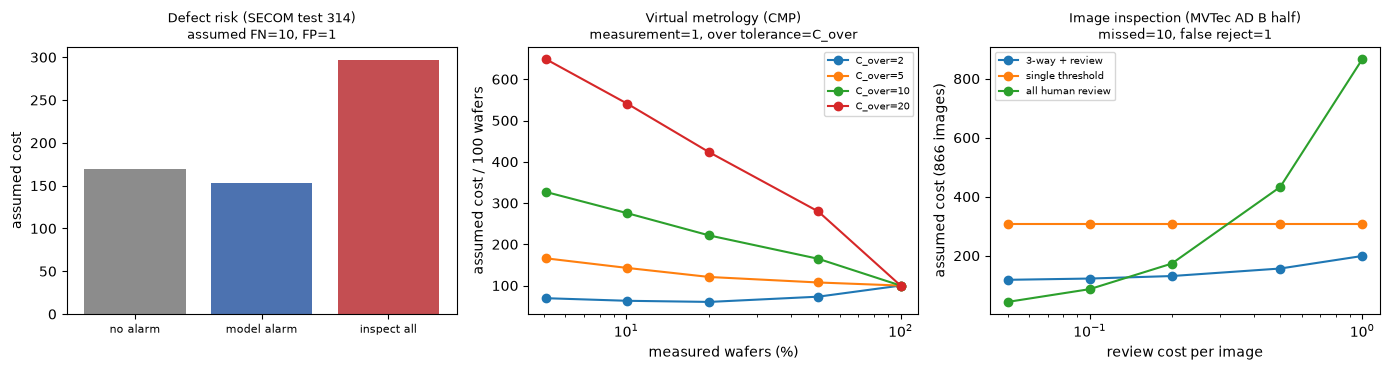

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ax = axes[0]
ax.bar(list(secom_cost), list(secom_cost.values()), color=["#8C8C8C", "#4C72B0", "#C44E52"])
ax.set_title("Defect risk (SECOM test 314)\nassumed FN=10, FP=1", fontsize=9); ax.set_ylabel("assumed cost")
ax.set_xticks(range(3), ["no alarm", "model alarm", "inspect all"], fontsize=8)
ax = axes[1]
for c_over, g in vm_cost.groupby("C_over"):
    g = g.sort_values("measured_pct"); ax.plot(g["measured_pct"], g["cost_per_100"], marker="o", label=f"C_over={c_over}")
ax.set_xscale("log"); ax.set_xlabel("measured wafers (%)"); ax.set_ylabel("assumed cost / 100 wafers")
ax.set_title("Virtual metrology (CMP)\nmeasurement=1, over tolerance=C_over", fontsize=9); ax.legend(fontsize=7)
ax = axes[2]
for pol, g in img_cost.groupby("policy"):
    ax.plot(g["C_review"], g["cost"], marker="o", label={"단일 임계값(자동)": "single threshold", "3단계(자동+재검토)": "3-way + review",
                                                          "전수 사람 판독": "all human review"}[pol])
ax.set_xscale("log"); ax.set_xlabel("review cost per image"); ax.set_ylabel(f"assumed cost ({n_img} images)")
ax.set_title("Image inspection (MVTec AD B half)\nmissed=10, false reject=1", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/16_cost_sensitivity.png", dpi=100); plt.show()

In [10]:
summary = pd.DataFrame([
    {"PoC": "불량 위험 예측", "모델 출력": "불량 확률", "행동": "재검사 알람", "평가 대상": f"SECOM 평가 {len(secom)}건",
     "행동 건수": int(alarm.sum()), "잡은 문제": f"불량 {tp}/{n_fail}", "가정 비용(모델/기준)": f"{secom_cost['모델 알람(임계값 0.819)']} / 알람 없음 {secom_cost['알람 없음']}"},
    {"PoC": "가상계측", "모델 출력": "제거율 예측 + 구간", "행동": "추가 계측(10장에 1장)", "평가 대상": f"CMP 운영 {len(vm_pred)}건",
     "행동 건수": int(len(vm_fb)), "잡은 문제": f"허용오차 초과 {vm[vm.every == 10]['over_tol'].item():.1%}(미실측)",
     "가정 비용(모델/기준)": f"{vm_cost.query('C_over == 5 and every == 10')['cost_per_100'].item()} / 전수 계측 100 (100장당)"},
    {"PoC": "이미지 판독", "모델 출력": "이상 점수 + Heatmap", "행동": "엔지니어 재검토", "평가 대상": f"MVTec AD B {n_img}장",
     "행동 건수": tw["review"], "잡은 문제": f"자동 통과 속 불량 {tw['missed_in_pass']}/{n_def}",
     "가정 비용(모델/기준)": f"{img_cost.query('C_review == 0.2 and policy == \"3단계(자동+재검토)\"')['cost'].item()} / 단일 임계값 {img_cost.query('C_review == 0.2 and policy == \"단일 임계값(자동)\"')['cost'].item()}"},
])
print(summary.to_string(index=False))

     PoC           모델 출력             행동           평가 대상  행동 건수              잡은 문제              가정 비용(모델/기준)
불량 위험 예측           불량 확률         재검사 알람   SECOM 평가 314건      5            불량 2/17           153 / 알람 없음 170
    가상계측     제거율 예측 + 구간 추가 계측(10장에 1장)    CMP 운영 1695건    171 허용오차 초과 29.5%(미실측) 142.7 / 전수 계측 100 (100장당)
  이미지 판독 이상 점수 + Heatmap       엔지니어 재검토 MVTec AD B 866장     85  자동 통과 속 불량 10/630      131.0 / 단일 임계값 308.0


In [11]:
out = {"secom": {"n": len(secom), "fail": n_fail, "threshold": row6["threshold"], "alarm": int(alarm.sum()), "tp": tp, "fp": fp,
                 "matches_ch6": bool((tp, fp) == (row6["tp"], row6["fp"])), "cost": secom_cost},
       "vm": {"n_pred": len(vm_pred), "n_feedback": len(vm_fb), "cost": vm_cost.to_dict("records")},
       "image": {"n": n_img, "n_defect": n_def, "three_way": tw, "single": single, "cost": img_cost.to_dict("records")},
       "summary": summary.to_dict("records")}
Path("results/16_integration.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=float), encoding="utf-8")

6689